In [1]:
import pandas as pd
import numpy as np
np.set_printoptions(legacy="1.25")

In [2]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

#!wget $data -O lead-scoring.csv

In [3]:
df = pd.read_csv('lead-scoring.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
df.head().T

,0,1,2,3,4
lead_source,organic_search,social_media,referral,paid_ads,referral
industry,technology,technology,retail,manufacturing,manufacturing
employment_status,employed,employed,employed,student,student
location,europe,south_america,europe,NaN,north_america
annual_income,88160.0,72688.0,44697.0,NaN,24062.0
number_of_courses_viewed,3,3,3,3,4
interaction_count,4,7,4,6,5
lead_score,0.64,0.72,0.58,0.57,0.62
converted,1,1,1,0,1


In [5]:
df.columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='str')

In [6]:
df.columns = df.columns.str.lower().str.replace(' ','_')

In [7]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [8]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [9]:
categorical = list(df.dtypes[df.dtypes=='str'].index)

In [10]:
for i in categorical:
    df[i] = df[i].str.lower().str.replace(' ','_')

In [11]:
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count',
             'lead_score']

In [12]:
for i in categorical:
     df[i] = df[i].fillna('NA')

In [13]:
for i in numerical:
     df[i] = df[i].fillna(0)

In [14]:
from sklearn.model_selection import train_test_split

In [15]:
df_full_train, df_test = train_test_split(df, test_size= 0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size= 0.25, random_state=1)

In [16]:
df_train.head().T

,4740,1452,2846,4670,168
lead_source,paid_ads,paid_ads,NA,paid_ads,organic_search
industry,technology,retail,finance,finance,finance
employment_status,employed,employed,employed,employed,employed
location,asia,asia,NA,NA,asia
annual_income,80198.0,50548.0,76300.0,80371.0,73567.0
number_of_courses_viewed,5,2,0,2,2
interaction_count,9,5,3,6,4
lead_score,0.91,0.48,0.42,0.49,0.48
converted,1,0,0,0,1


In [17]:
from sklearn.metrics import roc_auc_score

In [18]:
auc_scores = []
for i in numerical:

    auc = roc_auc_score(df_train.converted.values, df_train[i].values)
    if auc < 0.5:
        auc = roc_auc_score(df_train.converted.values, -df_train[i].values)

    auc_scores.append((i, auc))

In [19]:
auc_scores

[('annual_income', 0.6081977776250831),
 ('number_of_courses_viewed', 0.7229894623989618),
 ('interaction_count', 0.7649203047563227),
 ('lead_score', 0.7882254810906102)]

In [20]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [21]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [22]:
from sklearn.feature_extraction import DictVectorizer

In [23]:
from sklearn.linear_model import LogisticRegression

In [24]:
def train(df_train, y_train):

    dicts = df_train[categorical+numerical].to_dict(orient = 'records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

In [25]:
def predict(df, dv, model):

    dicts = df[categorical+numerical].to_dict(orient = 'records')

    X = dv.transform(dicts)

    y_pred = model.predict_proba(X)[:,1]

    return y_pred

In [26]:
dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)

In [27]:
y_pred

array([0.54472295, 0.79005191, 0.50977882, 0.52913934, 0.82072017,
       0.54245972, 0.50178712, 0.54698383, 0.82553291, 0.40583727,
       0.91301561, 0.33581811, 0.3078986 , 0.42704772, 0.62192275,
       0.53665458, 0.41931913, 0.84087339, 0.79969125, 0.61790114,
       0.61625177, 0.68059912, 0.85605897, 0.80784865, 0.62045997,
       0.45970701, 0.54556694, 0.41221371, 0.72714005, 0.46812072,
       0.77222173, 0.79043872, 0.61433884, 0.78549743, 0.49753403,
       0.66077266, 0.69804748, 0.7689654 , 0.65657485, 0.64127885,
       0.66509096, 0.57942799, 0.67830929, 0.61186087, 0.86890227,
       0.41469665, 0.84130122, 0.74229349, 0.68028533, 0.71891426,
       0.86417924, 0.64043347, 0.54246978, 0.70225148, 0.27894882,
       0.70826471, 0.62310687, 0.47781739, 0.37914002, 0.69936026,
       0.52032849, 0.69977687, 0.75148933, 0.58087478, 0.47001782,
       0.56863462, 0.91297177, 0.79972016, 0.82206537, 0.36140182,
       0.66132377, 0.52330037, 0.79295454, 0.72068061, 0.71234

In [28]:
auc = roc_auc_score(y_val, y_pred)
np.round(auc,3)

0.732

In [29]:
thresholds = np.linspace(0, 1, num= 101)
precisions = []
recalls = []
for t in thresholds:

    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (actual_positive & predict_positive).sum()
    tn = (actual_negative & predict_negative).sum()
    fp = (actual_negative & predict_positive).sum()
    fn = (actual_positive & predict_negative).sum()

    p = tp/(tp+fp)
    r = tp/(tp+fn)
    
    precisions.append(p)
    recalls.append(r)

/tmp/ipykernel_4108/669359453.py:16: RuntimeWarning: invalid value encountered in scalar divide
  p = tp/(tp+fp)


In [30]:
from matplotlib import pyplot as plt

<function matplotlib.pyplot.legend(*args, **kwargs) -> 'Legend'>

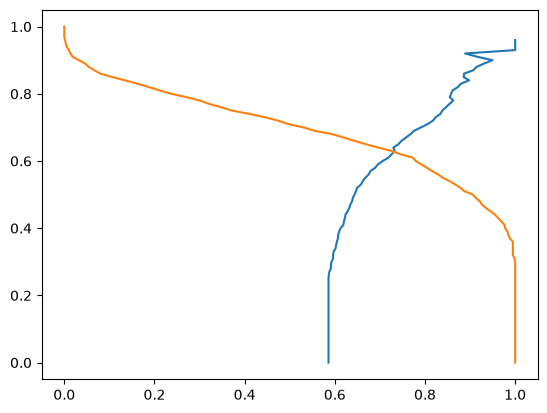

In [31]:
plt.plot(precisions, thresholds, label = 'precisions')
plt.plot(recalls, thresholds, label = 'recalls')
plt.legend

In [32]:
precisions

[0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.586,
 0.5865865865865866,
 0.5877632898696088,
 0.591321897073663,
 0.591321897073663,
 0.5925176946410515,
 0.5963302752293578,
 0.5961145194274029,
 0.5973360655737705,
 0.6016511867905057,
 0.6028955532574974,
 0.6047717842323651,
 0.6069182389937107,
 0.6073684210526316,
 0.6095238095238096,
 0.6128342245989304,
 0.6190476190476191,
 0.6200873362445415,
 0.6225165562913907,
 0.623608017817372,
 0.6281179138321995,
 0.6320645905420992,
 0.6343457943925234,
 0.6382978723404256,
 0.6399521531100478,
 0.6436363636363637,
 0.6467661691542289,
 0.6494325346784363,
 0.6580310880829016,
 0.6618229854689565,
 0.6675712347354138,
 0.675,
 0.6789772727272727,
 0.6896046852122987,
 0.6956521739130435,
 0.7063369397217929,
 0.719047619047619,
 0.7259136212624585,
 0.7327586206896551,
 0.72987477

In [33]:
recalls

[1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 0.9982935153583617,
 0.9948805460750854,
 0.9948805460750854,
 0.9948805460750854,
 0.9948805460750854,
 0.9948805460750854,
 0.9880546075085325,
 0.984641638225256,
 0.9829351535836177,
 0.9778156996587031,
 0.9761092150170648,
 0.9692832764505119,
 0.962457337883959,
 0.9556313993174061,
 0.9453924914675768,
 0.9351535836177475,
 0.9266211604095563,
 0.9215017064846417,
 0.9129692832764505,
 0.9061433447098977,
 0.8873720136518771,
 0.878839590443686,
 0.8668941979522184,
 0.8549488054607508,
 0.8395904436860068,
 0.8293515358361775,
 0.8156996587030717,
 0.8037542662116041,
 0.7918088737201365,
 0.7798634812286689,
 0.773037542662116,
 0.7457337883959044,
 0.7252559726962458,
 0.6962457337883959,
 0.6689419795221843,
 0.643344709897611,
 0.6194539249146758,
 0.5938566552901023,
 0.5546075085324232,


In [34]:
F1 = []
for i in range(len(thresholds)):

    f = (2*precisions[i]*recalls[i])/(precisions[i]+recalls[i])

    F1.append(f)

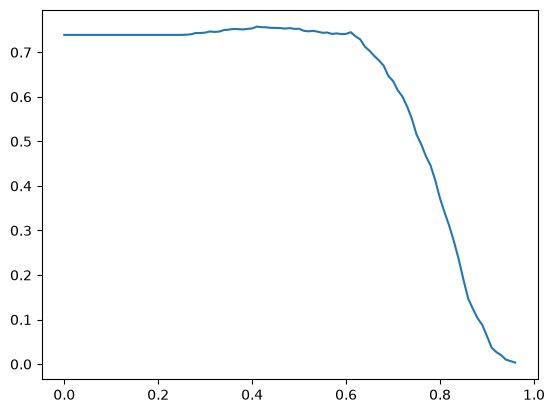

In [35]:
plt.plot(thresholds, F1)

In [36]:
max(F1)

0.7576158940397352

In [37]:
thresholds[F1.index(max(F1))]

0.41000000000000003

In [38]:
from sklearn.model_selection import KFold

In [41]:
def train(df_train, y_train):

    dicts = df_train[categorical+numerical].to_dict(orient = 'records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

In [42]:
def predict(df, dv, model):

    dicts = df[categorical+numerical].to_dict(orient = 'records')

    X = dv.transform(dicts)

    y_pred = model.predict_proba(X)[:,1]

    return y_pred

In [44]:
n_splits = 5
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
AUC_scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train)
    
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    AUC_scores.append(auc)
    

In [53]:
AUC_scores

[0.7305601027122453,
 0.7295726148196622,
 0.7363428071259397,
 0.7412454717957564,
 0.7209138590326581]

In [52]:
np.std(AUC_scores).round(3)

0.007

In [54]:
def train(df_train, y_train, C):

    dicts = df_train[categorical+numerical].to_dict(orient = 'records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

In [57]:
n_splits = 5
kfold = KFold(n_splits=5, shuffle=True, random_state=1)


for C in [0.000001, 0.001, 1]:
    AUC_scores = []
    
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
    
        y_train = df_train.converted.values
        y_val = df_val.converted.values
    
        dv, model = train(df_train, y_train, C)
        
        y_pred = predict(df_val, dv, model)
    
        auc = roc_auc_score(y_val, y_pred)
        AUC_scores.append(auc)
    print('C: %s; Mean AUC: %.3f; STD AUC: %.3f' % (C, np.mean(AUC_scores), np.std(AUC_scores)))

C: 1e-06; Mean AUC: 0.617; STD AUC: 0.019
C: 0.001; Mean AUC: 0.749; STD AUC: 0.010
C: 1; Mean AUC: 0.732; STD AUC: 0.007
